In [ ]:
%pip install puremacro


# Perturbación de tercer orden confiable: oráculos exactos, Dynare en vivo y un punto ciego

**Cuando un modelo DSGE se resuelve a tercer orden, ¿en qué coeficientes podemos confiar, y cómo sabríamos si alguno estuviera mal?**

Una solución de tercer orden añade riesgo a las reglas de decisión: un desplazamiento precautorio constante en segundo orden, y respuestas que cambian con el nivel de riesgo en tercer orden. Esos términos salen de una cadena de ecuaciones tensoriales y es fácil equivocarse en ellos sin que ninguna trayectoria simulada lo muestre. Este cuaderno verifica el solucionador de tercer orden de puremacro contra dos modelos con solución en forma cerrada y contra corridas reales de Dynare, y luego pregunta qué dice la solución verificada.

| Ficha de replicación | |
|---|---|
| Resultados verificados | Cada tensor de las reglas de decisión hasta tercer orden, las trayectorias simuladas con poda y sus momentos muestrales, y los momentos exactos de la solución con poda |
| Oráculos | Formas cerradas (un derecho sobre un pago cúbico; el modelo de crecimiento de Brock y Mirman), Dynare 7.0 ejecutado en MATLAB R2026a sobre cinco modelos en órdenes 2 y 3, y los momentos con poda y las simulaciones largas de Dynare 8 sobre seis modelos, todo congelado con hashes SHA-256; puremacro no calculó ningún valor de referencia |
| Datos | Ninguno; solo calibraciones de modelos |
| Solucionador evaluado | `load_mod(..., order=3)`, que devuelve la solución con poda de Andreasen, Fernández-Villaverde y Rubio-Ramírez (2018) |
| Aceptación | Error relativo menor que 1e-12 frente a las formas cerradas; la propia tolerancia de los archivos de referencia frente a Dynare (absoluta 1e-10, relativa 1e-9) |
| Veredicto | Lo imprime el cuadro de verificación al final, a partir de los errores calculados |

## El método en matemáticas

La perturbación de Dynare escribe cada variable como función de los estados rezagados $\hat x$, los choques $u$ y una escala $\sigma$ de los choques, y la expande alrededor del estado estacionario determinista:
$$y=y^*+g_x\hat x+g_u u+\tfrac12\left(g_{xx}\hat x^{\otimes2}+2g_{xu}\,\hat x\otimes u+g_{uu}u^{\otimes2}+g_{\sigma\sigma}\sigma^2\right)+\tfrac16\left(g_{xxx}\hat x^{\otimes3}+3g_{xxu}\,\hat x^{\otimes2}\otimes u+3g_{xuu}\,\hat x\otimes u^{\otimes2}+g_{uuu}u^{\otimes3}\right)+\tfrac12\left(g_{x\sigma\sigma}\hat x+g_{u\sigma\sigma}u\right)\sigma^2 .$$
Los términos de primer orden cumplen la equivalencia cierta. El riesgo entra por $g_{\sigma\sigma}$, un desplazamiento constante, y por $g_{x\sigma\sigma}$ y $g_{u\sigma\sigma}$, que hacen que la respuesta a estados y choques dependa de cuánto riesgo hay. La poda simula por separado las partes de primer, segundo y tercer orden para que las trayectorias se mantengan estables.

## Intuición

**Intuición.** Una trayectoria que coincide es evidencia débil de que un tensor es correcto. Cada observación simulada contrae un tensor con un producto de estados y choques, y familias enteras de tensores equivocados dan la misma contracción. Las comprobaciones fuertes son dos: comparar cada entrada del tensor con una referencia, y usar un modelo cuyos tensores se conocen exactamente. Los términos de riesgo merecen la mayor atención: eran 25% demasiado grandes en un modelo con forma cerrada antes de la versión 4.3.0, y un error distinto en una derivada mixta del modelo RBC sobrevivió a las comparaciones de trayectorias hasta que los tensores de Dynare en vivo lo expusieron.

## Código resuelto

Los tensores se comparan entrada por entrada después de alinear las columnas por los nombres de estados y choques, porque dos programas pueden ordenar los estados de manera distinta.

In [1]:
from pathlib import Path
from itertools import product
from math import prod
import hashlib
import json
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()
from puremacro.dsge import diagnose_perturbation, load_mod

# A variable with no first-order response (the claim's price) has no first-order variance
# decomposition; theoretical_moments warns about that, and it is expected here.
warnings.filterwarnings("ignore", message="forecast-error variance is zero")

# The index pattern of each unfolded tensor: x runs over states, u over shocks.
AXES = {"ghx": "x", "ghu": "u", "ghxx": "xx", "ghxu": "xu", "ghuu": "uu", "ghs2": "",
        "ghxxx": "xxx", "ghxxu": "xxu", "ghxuu": "xuu", "ghuuu": "uuu", "ghxss": "x", "ghuss": "u"}
RISK_TERMS = ("ghs2", "ghxss", "ghuss")
# The RBC model of Dynare's live check, byte for byte (section 2 verifies its hash).
RBC = ("var y c k a; varexo e;\nparameters alpha beta delta rho; alpha=.33;beta=.99;delta=.025;rho=.9;\n"
       "model;\n1/c=beta/c(+1)*(alpha*exp(a(+1))*k^(alpha-1)+1-delta);\nk=exp(a)*k(-1)^alpha+(1-delta)*k(-1)-c;\n"
       "a=rho*a(-1)+e;\ny=exp(a)*k(-1)^alpha;\nend;\n"
       "initval; y=3.0153277085137282;c=2.3066172319875173;k=28.348419061048435;a=0;end;\n"
       "shocks;var e;stderr .01;end;\n")

checks = []  # one row per checked result


def record(result, measured, bound, verdict):
    checks.append({"result": result, "measured": float(measured), "bound": bound, "verdict": verdict})


def labelled_tensors(sol, states=None, shocks=None, fields=tuple(AXES)):
    """Decision-rule tensors as DataFrames with columns labelled by state and shock names."""
    dr = sol.decision_rules()
    own_x, own_u = list(dr.state_variables), list(dr.shock_names)
    states = list(states) if states is not None else own_x
    shocks = list(shocks) if shocks is not None else own_u
    out = {}
    for field in fields:
        axes = AXES[field]
        own = list(product(*(own_x if a == "x" else own_u for a in axes)))
        cols = list(product(*(states if a == "x" else shocks for a in axes)))
        mat = np.asarray(getattr(dr, field)).reshape(len(dr.variable_names), -1)
        data = np.zeros((len(dr.variable_names), len(cols)))
        for j_col, c in enumerate(cols):
            if c in own:
                data[:, j_col] = mat[:, own.index(c)]
        out[field] = pd.DataFrame(data, index=list(dr.variable_names), columns=cols)
    return dr, out


def claim_to_cube(beta, rho, s):
    """y_t = beta E_t y_{t+1} + x_t^3: the price of a claim to the convex payoff x^3, x an AR(1)."""
    return load_mod(f"var y x; varexo e; parameters beta rho; beta={beta!r}; rho={rho!r};\n"
                    "model; x = rho*x(-1) + e; y = beta*y(+1) + x^3; end;\n"
                    f"initval; x=0; y=0; end;\nshocks; var e; stderr {s!r}; end;\n",
                    states=["x"], order=3)


def cube_closed_form(beta, rho, s):
    """The exact solution y = A x^3 + B x and its third-order tensors."""
    A = 1.0 / (1.0 - beta * rho**3)
    B = 3.0 * beta * A * rho * s**2 / (1.0 - beta * rho)
    return A, B, {"ghxxx": 6 * A * rho**3, "ghxxu": 6 * A * rho**2, "ghxuu": 6 * A * rho, "ghuuu": 6 * A,
                  "ghxss": 2 * B * rho, "ghuss": 2 * B}

### 1. Dos modelos cuya solución de tercer orden se conoce exactamente

**Un derecho sobre un pago cúbico.** Con $x_t=\rho x_{t-1}+e_t$ y $\operatorname{Var}(e)=s^2$, el precio $y_t=\beta E_ty_{t+1}+x_t^3$ es exactamente $y=Ax^3+Bx$, donde $A=1/(1-\beta\rho^3)$ y $B=3\beta A\rho s^2/(1-\beta\rho)$. Todos los tensores de $y$ se siguen de ahí, incluidos los términos de riesgo $g_{x\sigma\sigma}=2B\rho$ y $g_{u\sigma\sigma}=2B$; este es el caso de prueba en el que los términos de riesgo anteriores a la versión 4.3.0 eran 25% demasiado grandes. La comprobación se hace con la calibración de ese hallazgo y con otras once aleatorias.

**Brock y Mirman (1972).** Con utilidad logarítmica y depreciación completa, la política es exactamente $k_t=\alpha\beta e^{a_t}k_{t-1}^\alpha$ y $c_t=(1-\alpha\beta)e^{a_t}k_{t-1}^\alpha$ con cualquier nivel de riesgo. Cada derivada es un producto de potencias, y todo término de riesgo debe ser cero.

In [2]:
calibrations = [(0.95, 0.8, 0.1)]  # the calibration of the 19 September 2026 review
rng = np.random.default_rng(2026)
calibrations += [(rng.uniform(0.5, 0.99), rng.uniform(-0.9, 0.95), rng.uniform(0.01, 0.5)) for _ in range(11)]
worst_cube = 0.0
for beta, rho, s in calibrations:
    _, T = labelled_tensors(claim_to_cube(beta, rho, s))
    A, B, exact = cube_closed_form(beta, rho, s)
    for field in AXES:
        target_y = exact.get(field, 0.0)
        target_x = {"ghx": rho, "ghu": 1.0}.get(field, 0.0)
        worst_cube = max(worst_cube, np.max(np.abs(T[field].loc["y"] - target_y)) / max(1.0, abs(target_y)),
                         np.max(np.abs(T[field].loc["x"] - target_x)) / max(1.0, abs(target_x)))
_, T = labelled_tensors(claim_to_cube(*calibrations[0]))
_, _, exact = cube_closed_form(*calibrations[0])
before_fix = {"ghxss": 0.369937695, "ghuss": 0.462422118}  # reported by the review, release 4.2.0
print(pd.DataFrame({"solver": {f: T[f].loc["y"].iloc[0] for f in exact}, "closed form": exact,
                    "before 4.3.0": before_fix}).round(9).to_string(na_rep=""))
print(f"Largest relative error over {len(calibrations)} calibrations: {worst_cube:.1e}")

alpha, beta_bm, rho_bm, s_bm = 0.33, 0.96, 0.9, 0.05
k_ss = (alpha * beta_bm) ** (1.0 / (1.0 - alpha))
c_ss = (1.0 - alpha * beta_bm) * k_ss**alpha
brock_mirman = load_mod(
    f"var c k a; varexo e; parameters alpha beta rho; alpha={alpha!r}; beta={beta_bm!r}; rho={rho_bm!r};\n"
    "model; 1/c = beta/c(+1)*alpha*exp(a(+1))*k^(alpha-1); c + k = exp(a)*k(-1)^alpha; a = rho*a(-1) + e; end;\n"
    f"initval; k={k_ss!r}; c={c_ss!r}; a=0; end;\nshocks; var e; stderr {s_bm!r}; end;\n", order=3)
_, T = labelled_tensors(brock_mirman)
level = {"k": alpha * beta_bm * k_ss**alpha, "c": c_ss}
worst_bm, worst_risk = 0.0, 0.0
for field, axes in AXES.items():
    for var in T[field].index:
        for col, value in T[field].loc[var].items():
            n_k, n_a = col.count("k"), col.count("a")
            if field in RISK_TERMS:
                worst_risk = max(worst_risk, abs(value))
                continue
            if var == "a":   # a = rho a(-1) + e is linear
                target = rho_bm if (field, col) == ("ghx", ("a",)) else 1.0 if field == "ghu" else 0.0
            else:            # level * alpha(alpha-1)...(alpha-n_k+1) k^-n_k * rho^n_a; shock derivatives are 1
                target = level[var] * prod(alpha - m for m in range(n_k)) * k_ss ** (-n_k) * rho_bm**n_a
            worst_bm = max(worst_bm, abs(value - target) / max(1.0, abs(target)))
print(f"Brock-Mirman: largest relative error over every tensor {worst_bm:.1e}; largest risk term {worst_risk:.1e}")
record("Exact oracle: claim to x^3, every tensor, 12 calibrations (relative)", worst_cube, 1e-12, "exact")
record("Exact oracle: Brock-Mirman policy, every tensor (relative)", worst_bm, 1e-12, "exact")
record("Exact oracle: Brock-Mirman risk terms (certainty equivalence)", worst_risk, 1e-14, "exact")
assert worst_cube < 1e-12 and worst_bm < 1e-12 and worst_risk < 1e-14

          solver  closed form  before 4.3.0
ghxxx   5.981308     5.981308              
ghxxu   7.476636     7.476636              
ghxuu   9.345794     9.345794              
ghuuu  11.682243    11.682243              
ghxss   0.295950     0.295950      0.369938
ghuss   0.369938     0.369938      0.462422
Largest relative error over 12 calibrations: 3.3e-16
Brock-Mirman: largest relative error over every tensor 1.7e-15; largest risk term 2.0e-18


### 2. Cinco modelos frente a Dynare 7.0 en vivo

El repositorio congela las reglas de decisión y las simulaciones con poda del propio Dynare para cinco modelos en órdenes 2 y 3 en `tests/fixtures/dynare_live`, con un manifiesto de hashes SHA-256; ningún valor de referencia en ellos fue calculado por puremacro. Cada modelo se resuelve aquí de nuevo, se compara cada tensor después de alinear filas y columnas por nombre, y el modelo se simula con las 2,500 innovaciones de Dynare. Estos archivos vienen con el repositorio y no con el paquete, así que en una sesión del navegador esta sección informa que no se ejecutó.

In [3]:
LIVE = repo / "tests" / "fixtures" / "dynare_live"
sha256 = lambda data: hashlib.sha256(data).hexdigest()


def sample_moments(path, burn):
    x = path[burn:]
    d = x - x.mean(axis=0)
    lag = (x[1:] - x[1:].mean(axis=0)).T @ (x[:-1] - x[:-1].mean(axis=0)) / (len(x) - 2)
    return {"mean": x.mean(axis=0), "covariance": d.T @ d / (len(x) - 1), "lag-1 covariance": lag}


dynare = None
if (LIVE / "manifest.json").is_file():
    manifest = json.loads((LIVE / "manifest.json").read_text())
    atol, rtol, burn = manifest["atol"], manifest["rtol"], manifest["burn"]
    rows, bad_hashes = [], 0
    for name, info in manifest["cases"].items():
        files = {"model": LIVE / info["model"], "reference": LIVE / f"{name}.npz",
                 "innovations": LIVE / f"{Path(info['model']).stem}_innovations.csv"}
        bad_hashes += sum(sha256(path.read_bytes()) != info[f"{key}_sha256"] for key, path in files.items())
        sol = load_mod(files["model"].read_text(), order=info["order"])
        with np.load(files["reference"]) as ref:
            variables, states, shocks = (list(ref[k]) for k in ("variable_names", "state_names", "shock_names"))
            fields = list(AXES)[: 6 if info["order"] == 2 else 12]
            dr, T = labelled_tensors(sol, states, shocks, fields)
            tensor_ok = all(np.allclose(T[f].loc[variables].to_numpy(), ref[f], atol=atol, rtol=rtol) for f in fields)
            tensor_err = {f: np.max(np.abs(T[f].loc[variables].to_numpy() - ref[f])) for f in fields}
            ys_err = np.max(np.abs(dr.ys.loc[variables].to_numpy() - ref["ys"]))
            eps = ref["innovations"][:, [shocks.index(u) for u in sol.shock_names]]
            sim = sol.simulate(periods=len(eps), burn=0, shocks=eps)
            path = pd.concat([sim.states, sim.controls], axis=1)[variables].to_numpy() + dr.ys.loc[variables].to_numpy()
            ours, theirs = sample_moments(path, burn), sample_moments(ref["path"], burn)
            rows.append({"case": name, "order": info["order"], "tensors": max(tensor_err.values()),
                         "worst tensor": max(tensor_err, key=tensor_err.get), "steady state": ys_err,
                         "path": np.max(np.abs(path - ref["path"])),
                         "moments": max(np.max(np.abs(ours[k] - theirs[k])) for k in ours),
                         "within tolerance": tensor_ok and np.allclose(path, ref["path"], atol=atol, rtol=rtol)})
    dynare = pd.DataFrame(rows).set_index("case")
    print(dynare.to_string(float_format=lambda v: f"{v:.1e}"))
    same_rbc = sha256(RBC.encode()) == manifest["cases"]["rbc_order3"]["model_sha256"]
    print(f"Fixture hashes that differ from the manifest: {bad_hashes}; the RBC text above is the file Dynare ran: {same_rbc}")
    record("Dynare 7.0: fixture files whose hash differs from the manifest", bad_hashes, 0, "provenance")
    record("Dynare 7.0: largest tensor error, 10 cases", dynare["tensors"].max(), atol, "independent")
    record("Dynare 7.0: largest simulated-path error", dynare["path"].max(), atol, "independent")
    record("Dynare 7.0: largest sample-moment error", dynare["moments"].max(), atol, "independent")
    assert bad_hashes == 0 and same_rbc and dynare["within tolerance"].all()
else:
    print("Not run: tests/fixtures/dynare_live is part of the repository checkout, not of the installed package.")
    for result in ("fixture files whose hash differs from the manifest", "largest tensor error, 10 cases",
                   "largest simulated-path error", "largest sample-moment error"):
        record(f"Dynare 7.0: {result}", np.nan, "not run", "not run")

                             order  tensors worst tensor  steady state    path  moments  within tolerance
case                                                                                                     
correlated_cubic_order2          2  0.0e+00          ghx       0.0e+00 1.4e-17  2.4e-17              True
correlated_cubic_order3          3  8.9e-16        ghxxx       0.0e+00 1.8e-15  2.2e-16              True
nonlinear_multishock_order2      2  5.6e-17          ghx       0.0e+00 5.6e-17  6.9e-18              True
nonlinear_multishock_order3      3  1.1e-15        ghuuu       0.0e+00 5.6e-17  6.2e-17              True
nonlinear_state_order2           2  1.4e-17         ghs2       0.0e+00 5.6e-17  2.8e-17              True
nonlinear_state_order3           3  1.1e-15        ghuuu       0.0e+00 5.6e-17  7.6e-17              True
quadratic_feedback_order2        2  4.4e-16         ghxx       0.0e+00 2.2e-16  1.1e-16              True
quadratic_feedback_order3        3  4.4e-16   

### 3. Lo que una comparación de trayectorias no puede ver, y lo que sí ve la simetría de Schwarz

El 20 de septiembre de 2026 la comprobación en vivo encontró que el tensor $g_{xxu}$ del RBC difería en 0.0012928883 mientras todas las trayectorias simuladas coincidían. El error era antisimétrico en los dos índices de estado: sumaba un valor a la entrada (capital, tecnología) y lo restaba de la entrada (tecnología, capital). Cada observación contrae $g_{xxu}$ con $\hat x\otimes\hat x\otimes u$, que es simétrico en esos dos índices, así que el error se cancela en toda trayectoria simulada. Una comprobación interna de la simetría de Schwarz, $g_{xxu,(k,a,e)}=g_{xxu,(a,k,e)}$, detecta de inmediato la parte antisimétrica sin necesitar Dynare, mientras que un error simétrico en esa misma derivada cruzada pasa la prueba de Schwarz y exige un oráculo externo. Junto con `diagnose_perturbation()`, que distingue el condicionamiento de los bloques diagonales de Schur (`schur_block_condition`) del condicionamiento del operador completo de Sylvester (`curvature_operator_condition`), verifica los residuos algebraicos de las ecuaciones de Sylvester y de riesgo (`sylvester_residuals`) y reporta la reutilización de bloques simétricos (`sylvester_work`), la celda siguiente verifica la simetría de Schwarz de $g_{xxu}$ y mide lo que los errores plantados hacen en ambas pruebas.

In [4]:
rbc = load_mod(RBC, order=3)
rbc_diag = diagnose_perturbation(rbc, max_curvature_order=3)
sylv_res_max = max(rbc_diag.sylvester_residuals.values())
dr, T = labelled_tensors(rbc)
states, shocks = list(dr.state_variables), list(dr.shock_names)
cols = list(T["ghxxu"].columns)
i, j = cols.index((states[0], states[1], shocks[0])), cols.index((states[1], states[0], shocks[0]))
schwarz_err = float(np.max(np.abs(T["ghxxu"].iloc[:, i] - T["ghxxu"].iloc[:, j])))
size = 0.0012928883
planted = {"antisymmetric": np.zeros((len(dr.variable_names), len(cols))), "symmetric": np.zeros((len(dr.variable_names), len(cols)))}
planted["antisymmetric"][:, i], planted["antisymmetric"][:, j] = size, -size
planted["symmetric"][:, i] = planted["symmetric"][:, j] = size
sim = rbc.simulate(periods=2500, seed=0, burn=0)
x_lag = sim.states[states].to_numpy()[:-1]          # state deviations dated t-1
u = sim.shocks[shocks].to_numpy()[1:]
kron = np.einsum("ti,tj,tk->tijk", x_lag, x_lag, u).reshape(len(u), -1)   # columns follow product(states, states, shocks)
blind = pd.DataFrame({name: {"largest tensor error": np.max(np.abs(D)),
                             "Schwarz asymmetry |D(k,a,e) - D(a,k,e)|": np.max(np.abs(D[:, i] - D[:, j])),
                             "largest effect on a simulated observation": np.max(np.abs(kron @ D.T)) / 2}
                      for name, D in planted.items()})
print(f"Solved RBC g_xxu Schwarz asymmetry |g(k,a,e) - g(a,k,e)|: {schwarz_err:.2e}")
print(f"Sylvester algebraic residuals (max={sylv_res_max:.2e}):", {k: f"{v:.2e}" for k, v in rbc_diag.sylvester_residuals.items()})
print(rbc_diag.curvature_frame().to_string(index=False, float_format=lambda v: f"{v:.3e}"))
print(blind.to_string(float_format=lambda v: f"{v:.2e}"))
record("Internal symmetry: RBC g_xxu Schwarz check |g(k,a,e) - g(a,k,e)|", schwarz_err, 1e-15, "exact")
record("Internal algebra: RBC Sylvester residuals (ghxx, ghs2, ghxxx, ghxss, ghuss)", sylv_res_max, 1e-13, "exact")
record("Blind spot: path effect of the antisymmetric error", blind.loc["largest effect on a simulated observation", "antisymmetric"], 1e-15, "invisible")
assert schwarz_err < 1e-15 and sylv_res_max < 1e-13 and rbc_diag.sylvester_work[3].lu_cache_hits > 0
assert blind.loc["largest effect on a simulated observation", "antisymmetric"] < 1e-15
assert blind.loc["Schwarz asymmetry |D(k,a,e) - D(a,k,e)|", "antisymmetric"] > 2e-3
assert blind.loc["Schwarz asymmetry |D(k,a,e) - D(a,k,e)|", "symmetric"] == 0.0
assert blind.loc["largest effect on a simulated observation", "symmetric"] > 1e-10

Solved RBC g_xxu Schwarz asymmetry |g(k,a,e) - g(a,k,e)|: 3.47e-18
Sylvester algebraic residuals (max=9.03e-19): {'ghxx': '8.06e-19', 'ghs2': '0.00e+00', 'ghxxx': '9.03e-19', 'ghxss': '4.76e-22', 'ghuss': '8.47e-22'}
 order  schur_block_condition  curvature_operator_condition  coupling_amplification condition_method
     1              3.897e+02                     5.860e+03               1.504e+01      exact_2norm
     2              2.752e+02                     6.053e+04               2.200e+02      exact_2norm
     3              2.145e+02                     6.808e+05               3.174e+03      exact_2norm
                                           antisymmetric  symmetric
largest tensor error                            1.29e-03   1.29e-03
Schwarz asymmetry |D(k,a,e) - D(a,k,e)|         2.59e-03   0.00e+00
largest effect on a simulated observation       7.92e-23   2.41e-06


La figura principal resume la evidencia. A la izquierda, cada barra es el mayor desacuerdo con Dynare para un modelo y un orden, frente a la tolerancia de los archivos de referencia. A la derecha, los errores plantados: ambos tienen el mismo tamaño en el tensor, pero solo el simétrico llega a una trayectoria.

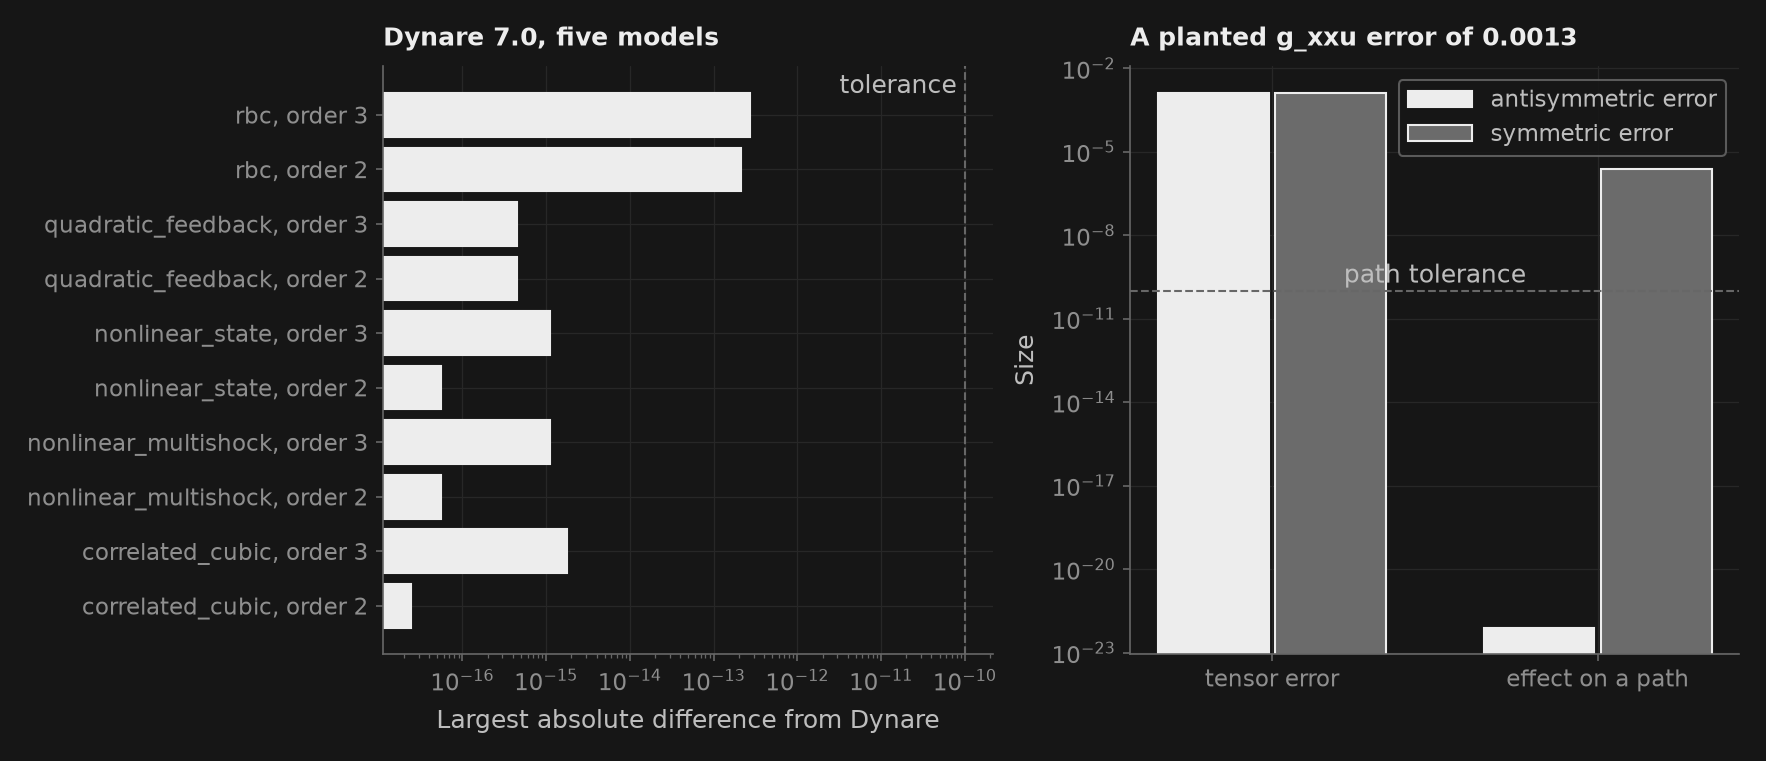

In [5]:
col = _nbstyle.palette(2)
fig, (ax1, ax2) = _nbstyle.figura(1, 2, figsize=(11.5, 4.8))
if dynare is not None:
    worst = dynare[["tensors", "path", "moments"]].max(axis=1).clip(lower=1e-18)
    ax1.barh(range(len(worst)), worst.to_numpy(), color=col[0], edgecolor=_nbstyle.TINTA)
    ax1.set_yticks(range(len(worst)), [c.replace("_order", ", order ") for c in worst.index])
    ax1.axvline(atol, color=_nbstyle.SPINE, lw=1.0, linestyle="--")
    ax1.annotate("tolerance", (atol, len(worst) - 0.6), textcoords="offset points", xytext=(-4, 0), ha="right",
                 color=_nbstyle.TEXTO)
    ax1.set(xscale="log", xlabel="Largest absolute difference from Dynare", title="Dynare 7.0, five models")
else:
    ax1.text(0.5, 0.5, "Dynare fixtures need\nthe repository checkout", ha="center", va="center",
             transform=ax1.transAxes, color=_nbstyle.TEXTO)
    ax1.set_axis_off()
labels = ["tensor error", "effect on a path"]
x = np.arange(2)
for k, name in enumerate(("antisymmetric", "symmetric")):
    values = blind.loc[["largest tensor error", "largest effect on a simulated observation"], name].clip(lower=1e-24).to_numpy()
    ax2.bar(x + (k - 0.5) * 0.36, values, width=0.34, color=col[k], edgecolor=_nbstyle.TINTA, label=f"{name} error")
ax2.axhline(1e-10, color=_nbstyle.SPINE, lw=1.0, linestyle="--")
ax2.annotate("path tolerance", (0.5, 1e-10), textcoords="offset points", xytext=(0, 4), ha="center",
             color=_nbstyle.TEXTO)
ax2.set_xticks(x, labels)
ax2.set(yscale="log", ylabel="Size", title="A planted g_xxu error of 0.0013")
ax2.legend(loc="upper right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

### 4. Lo que dice el tercer orden verificado

En el modelo RBC, la media ergódica del capital se sitúa $+0.0785\%$ por encima del estado estacionario determinista. Como muestra `risk_decomposition()`, ese desplazamiento no proviene del término de riesgo puro $\tfrac12(I-G)^{-1}g_{\sigma\sigma}\sigma^2$ (el estado estacionario riesgoso, que aquí es ligeramente negativo con utilidad logarítmica y $\delta=0.025$), sino de los términos positivos de curvatura de Jensen $\tfrac12(I-G)^{-1}[g_{xx}\operatorname{vec}(\Omega)+g_{uu}\operatorname{vec}(\sigma^2\Sigma_u)]$ aplicados a la dispersión de estados y choques. Como $g_{\sigma^3}=0$ y los momentos impares de choques gaussianos simétricos se anulan, la componente podada de tercer orden tiene media cero ($E[x_t^{(3)}]=0$), de modo que todo el desplazamiento de la media ergódica es de segundo orden y escala con la varianza $\sigma^2$. La descomposición con poda da una comprobación de simulación precisa por variable de control: la parte de primer orden tiene media cero, así que la media muestral de las partes de segundo y tercer orden estima el desplazamiento con poco ruido. Las respuestas a choques grandes se vuelven asimétricas, y el tercer orden las hace depender del nivel de riesgo. En el derecho sobre $x^3$, toda la respuesta del precio a noticias pequeñas es un efecto de riesgo de tercer orden, $B\,e$, proporcional a la varianza.

In [6]:
def responses(sol, size, horizon, sigma=1.0):
    """Order-1, order-2 and order-3 responses to one shock of `size`, with no further shocks."""
    e = np.zeros((horizon + 1, len(sol.shock_names)))
    e[0, 0] = size
    shocked = sol.simulate(periods=horizon + 1, shocks=e, burn=0, sigma=sigma)
    base = sol.simulate(periods=horizon + 1, shocks=np.zeros_like(e), burn=0, sigma=sigma)
    parts = {1: ["1st"], 2: ["1st", "2nd"], 3: ["1st", "2nd", "3rd"]}
    return {k: sum(pd.concat([getattr(shocked, f"states_{p}"), getattr(shocked, f"controls_{p}")], axis=1)
                   - pd.concat([getattr(base, f"states_{p}"), getattr(base, f"controls_{p}")], axis=1) for p in parts[k])
            for k in parts}


ys = dr.ys
decomp_k = rbc.risk_decomposition().loc["k"]
print("RBC capital ergodic-mean decomposition (% of steady state):",
      {k: round(float(100 * decomp_k[k] / ys["k"]), 4) for k in ("risk", "state_curvature", "shock_curvature", "ergodic_mean")})
shift = {scale: pd.concat(list(rbc.stochastic_steady_state(sigma=scale).values())) for scale in (1.0, 2.0, 3.0)}
scaling_error = max(abs(shift[m]["k"] / shift[1.0]["k"] / m**2 - 1.0) for m in (2.0, 3.0))
control_variate = {}
for scale in (1.0, 3.0):
    long = rbc.simulate(periods=100_000, seed=7, burn=2_000, sigma=scale)
    higher = pd.concat([long.states_2nd + long.states_3rd, long.controls_2nd + long.controls_3rd], axis=1)["k"].to_numpy()
    batches = higher.reshape(100, -1).mean(axis=1)                     # 100 batch means for the standard error
    control_variate[scale] = (higher.mean(), batches.std(ddof=1) / 10.0)
z_scores = {m: (control_variate[m][0] - shift[m]["k"]) / control_variate[m][1] for m in control_variate}
print("Capital ergodic mean minus steady state (% of steady state), by shock s.d. multiple: "
      + ", ".join(f"x{m:g} {100 * shift[m]['k'] / ys['k']:.4f}" for m in shift))
print("Simulated minus analytic shift, in standard errors: " + ", ".join(f"x{m:g} {z:+.2f}" for m, z in z_scores.items()))

asymmetry = {}
for n_sd in (3, 10):
    up, down = responses(rbc, 0.01 * n_sd, 40), responses(rbc, -0.01 * n_sd, 40)
    asymmetry[n_sd] = {k: np.max(np.abs(up[k]["y"] + down[k]["y"])) / np.max(np.abs(up[k]["y"])) for k in (1, 2, 3)}
print("Output asymmetry |r(+v) + r(-v)| / |r(+v)|:")
print(pd.DataFrame(asymmetry).rename(index=lambda k: f"order {k}", columns=lambda n: f"{n} s.d. shock")
      .to_string(float_format=lambda v: f"{v:.1e}"))
risk_effect = {m: responses(rbc, 0.01, 40, sigma=m)[3]["c"].iloc[0] for m in (1.0, 5.0)}
print(f"Impact response of consumption at 1x and 5x the volatility: {risk_effect[1.0]:.6e}, {risk_effect[5.0]:.6e}")

volatilities = np.array([0.05, 0.1, 0.15, 0.2, 0.25])
small = 1e-3
slopes = []
for s in volatilities:
    r = responses(claim_to_cube(0.95, 0.8, s), small, 0)
    A, B, _ = cube_closed_form(0.95, 0.8, s)
    slopes.append({"s": s, "order 1": r[1]["y"].iloc[0] / small, "order 2": r[2]["y"].iloc[0] / small,
                   "order 3": r[3]["y"].iloc[0] / small, "closed form B + A e^2": B + A * small**2})
slopes = pd.DataFrame(slopes).set_index("s")
print(slopes.to_string(float_format=lambda v: f"{v:.6e}"))
slope_error = np.max(np.abs(slopes["order 3"] / slopes["closed form B + A e^2"] - 1.0))
record("Risk-adjusted mean proportional to variance: largest |shift(m)/(m^2 shift(1)) - 1|", scaling_error, 1e-9, "exact")
record("Risk-adjusted mean against simulation (control variate), largest |z|", max(abs(z) for z in z_scores.values()), 4.0, "statistical")
record("Claim to x^3: order-3 news response against the closed form (relative)", slope_error, 1e-10, "exact")
assert scaling_error < 1e-9 and max(abs(z) for z in z_scores.values()) < 4.0 and slope_error < 1e-10
assert asymmetry[3][1] < 1e-12 and asymmetry[3][2] > 1e-3
assert np.allclose(slopes[["order 1", "order 2"]], 0.0, atol=1e-14)

RBC capital ergodic-mean decomposition (% of steady state): {'risk': -0.0045, 'state_curvature': 0.0705, 'shock_curvature': 0.0125, 'ergodic_mean': 0.0785}


Capital ergodic mean minus steady state (% of steady state), by shock s.d. multiple: x1 0.0785, x2 0.3138, x3 0.7061
Simulated minus analytic shift, in standard errors: x1 +1.41, x3 +1.40
Output asymmetry |r(+v) + r(-v)| / |r(+v)|:
         3 s.d. shock  10 s.d. shock
order 1       0.0e+00        0.0e+00
order 2       3.0e-02        9.5e-02
order 3       3.0e-02        9.5e-02
Impact response of consumption at 1x and 5x the volatility: 5.247545e-03, 5.252147e-03
           order 1       order 2      order 3  closed form B + A e^2
s                                                                   
0.05 -4.166667e-40 -4.166667e-40 4.624416e-02           4.624416e-02
0.10 -4.166667e-40 -4.166667e-40 1.849708e-01           1.849708e-01
0.15 -4.166667e-40 -4.166667e-40 4.161819e-01           4.161819e-01
0.20 -4.166667e-40 -4.166667e-40 7.398773e-01           7.398773e-01
0.25 -4.166667e-40 -4.166667e-40 1.156057e+00           1.156057e+00


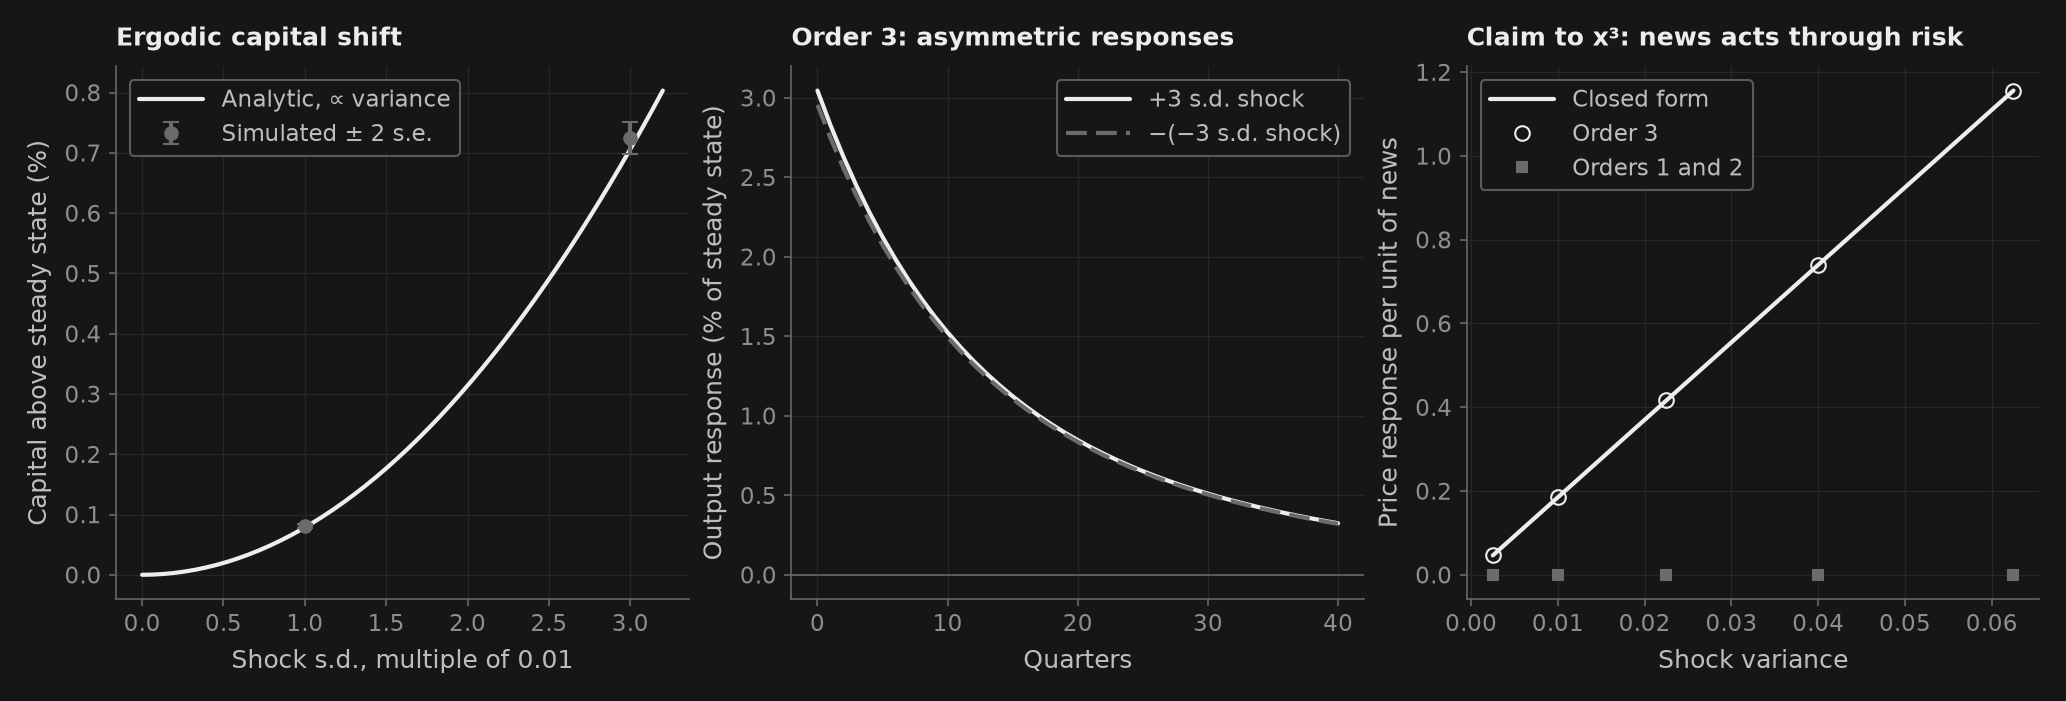

In [7]:
fig, (ax1, ax2, ax3) = _nbstyle.figura(1, 3, figsize=(13.5, 4.4))
grid = np.linspace(0.0, 3.2, 50)
ax1.plot(grid, 100 * shift[1.0]["k"] / ys["k"] * grid**2, color=col[0], lw=2.0, label="Analytic, ∝ variance")
for m, (mean, se) in control_variate.items():
    ax1.errorbar(m, 100 * mean / ys["k"], yerr=200 * se / ys["k"], fmt="o", color=col[1], ms=6, capsize=4,
                 label="Simulated ± 2 s.e." if m == 1.0 else None)
ax1.set(xlabel="Shock s.d., multiple of 0.01", ylabel="Capital above steady state (%)", title="Ergodic capital shift")
ax1.legend(loc="upper left", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)
up, down = responses(rbc, 0.03, 40), responses(rbc, -0.03, 40)
ax2.plot(100 * up[3]["y"] / ys["y"], color=col[0], lw=2.0, label="+3 s.d. shock")
ax2.plot(-100 * down[3]["y"] / ys["y"], color=col[1], lw=2.0, linestyle=_nbstyle.styles(2)[1], label="−(−3 s.d. shock)")
ax2.axhline(0.0, color=_nbstyle.SPINE, lw=0.8)
ax2.set(xlabel="Quarters", ylabel="Output response (% of steady state)", title="Order 3: asymmetric responses")
ax2.legend(loc="upper right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)
ax3.plot(volatilities**2, slopes["closed form B + A e^2"], color=col[0], lw=2.0, label="Closed form")
ax3.plot(volatilities**2, slopes["order 3"], "o", color=col[0], mfc="none", ms=7, label="Order 3")
ax3.plot(volatilities**2, slopes["order 2"], "s", color=col[1], ms=5, label="Orders 1 and 2")
ax3.set(xlabel="Shock variance", ylabel="Price response per unit of news", title="Claim to x³: news acts through risk")
ax3.legend(loc="upper left", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

### 5. Momentos exactos, y una laguna en la tabla de Dynare

La solución con poda es lineal en un estado aumentado, $z_t=[x^{(1)}_t;\,x^{(2)}_t;\,x^{(1)}_t\otimes x^{(1)}_t;\,x^{(3)}_t;\,x^{(1)}_t\otimes x^{(2)}_t;\,x^{(1)}_t\otimes x^{(1)}_t\otimes x^{(1)}_t]$. Sus innovaciones no están correlacionadas en el tiempo, así que `theoretical_moments()` calcula la media, la covarianza y las autocorrelaciones exactas (Andreasen, Fernández-Villaverde y Rubio-Ramírez 2018). Dos oráculos las verifican. Para el derecho sobre $x^3$, $y=Ax^3+Bx$ con $x$ gaussiana, de modo que el teorema de Isserlis da cada momento. Con $v=s^2/(1-\rho^2)$ y $r=\rho^k$,
$$\operatorname{Var}(y)=15A^2v^3+6ABv^2+B^2v,\qquad \operatorname{Cov}(y_t,y_{t-k})=A^2v^3(9r+6r^3)+6ABv^2r+B^2vr .$$
El segundo oráculo son los "theoretical moments based on pruned state space" de Dynare 8, congelados en `tests/fixtures/dynare_order3_pruned_moments.json` para los cinco modelos en vivo y el derecho. Las medias y varianzas de Dynare deberían coincidir con las de puremacro al nivel del redondeo. Sus autocorrelaciones no tienen por qué: la recursión de Dynare omite la correlación entre su innovación $x^{(1)}_{t-1}\otimes u_t\otimes u_t$ y los choques pasados. El archivo guarda además simulaciones del propio Dynare de cuatro millones de períodos, que dicen qué tabla es la correcta.

In [8]:
MOMENTS = repo / "tests" / "fixtures" / "dynare_order3_pruned_moments.json"


def cube_moments(beta, rho, s, lags):
    """Variance and autocorrelations of y = A x^3 + B x, by Isserlis' theorem."""
    A, B, _ = cube_closed_form(beta, rho, s)
    v = s**2 / (1.0 - rho**2)
    r = rho ** np.arange(1, lags + 1)
    var = 15 * A**2 * v**3 + 6 * A * B * v**2 + B**2 * v
    return var, (A**2 * v**3 * (9 * r + 6 * r**3) + 6 * A * B * v**2 * r + B**2 * v * r) / var


worst_moment = 0.0
for beta, rho, s in calibrations:
    th = claim_to_cube(beta, rho, s).theoretical_moments(lags=5)
    var, autocorr = cube_moments(beta, rho, s, 5)
    worst_moment = max(worst_moment, abs(th.covariance.loc["y", "y"] / var - 1.0),
                       np.max(np.abs(th.autocorr.loc["y"].to_numpy() - autocorr)))
print(f"Claim to x^3, 12 calibrations: largest error in Var(y) (relative) and five autocorrelations {worst_moment:.1e}")
record("Exact moments: claim to x^3, Var(y) and 5 autocorrelations, 12 calibrations", worst_moment, 1e-12, "exact")
assert worst_moment < 1e-12

acf = None
if MOMENTS.is_file() and LIVE.is_dir():
    frozen = json.loads(MOMENTS.read_text())
    rows, exact_acf = [], {}
    for name, case in frozen["cases"].items():
        text = case.get("model_text") or (LIVE / f"{name}.mod").read_text()
        th = load_mod(text, order=3).theoretical_moments(lags=5)
        names = case["variables"]
        theirs = np.array([np.diag(np.array(m)) for m in case["autocorr"]]).T
        exact_acf[name] = th.autocorr.loc[names]
        rows.append({"model": name, "hash matches": sha256(text.encode()) == case["model_sha256"],
                     "mean": np.max(np.abs(th.moments.loc[names, "Mean"].to_numpy() - case["mean"])),
                     "covariance": np.max(np.abs(th.covariance.loc[names, names].to_numpy() - np.array(case["var"]))),
                     "autocorrelation": np.max(np.abs(exact_acf[name].to_numpy() - theirs))})
    moments_vs_dynare = pd.DataFrame(rows).set_index("model")
    print("\nLargest absolute difference from Dynare 8's pruned moments:")
    print(moments_vs_dynare.to_string(float_format=lambda v: f"{v:.1e}"))
    sim_gap = 0.0
    for name, case in frozen["simulated"]["cases"].items():
        simulated = np.array([np.diag(np.array(m)) for m in case["autocorr"]]).T
        sim_gap = max(sim_gap, np.max(np.abs(simulated - exact_acf[name].loc[case["variables"]].to_numpy())))

    def lagged(case, variable):
        i = case["variables"].index(variable)
        return [m[i][i] for m in case["autocorr"]]

    claim = frozen["cases"]["claim_to_cube"]
    acf = {"claim": pd.DataFrame({"closed form": cube_moments(0.95, 0.8, 0.1, 5)[1],
                                  "puremacro": exact_acf["claim_to_cube"].loc["y"].to_numpy(),
                                  "Dynare's table": lagged(claim, "y")}, index=range(1, 6)),
           "cubic": pd.DataFrame({"Dynare's simulation": lagged(frozen["simulated"]["cases"]["correlated_cubic"], "y"),
                                  "puremacro": exact_acf["correlated_cubic"].loc["y"].to_numpy(),
                                  "Dynare's table": lagged(frozen["cases"]["correlated_cubic"], "y")}, index=range(1, 6))}
    for key, title in (("claim", "Claim to x^3"), ("cubic", "correlated_cubic.mod")):
        print(f"\n{title}: autocorrelation of y by lag")
        print(acf[key].to_string(float_format=lambda v: f"{v:.4f}"))
    print(f"\nDynare's own simulations against puremacro's exact autocorrelations, 3 models: largest gap {sim_gap:.1e}")
    record("Dynare 8 moment fixtures whose model hash differs", (~moments_vs_dynare["hash matches"]).sum(), 0, "provenance")
    record("Dynare 8: pruned means and covariances, 6 models (largest error)",
           moments_vs_dynare[["mean", "covariance"]].to_numpy().max(), 1e-10, "independent")
    record("Dynare 8's own 4e6-period simulations against exact autocorrelations (largest gap)", sim_gap, 3e-3, "statistical")
    assert moments_vs_dynare["hash matches"].all() and moments_vs_dynare[["mean", "covariance"]].to_numpy().max() < 1e-10
    assert sim_gap < 3e-3 and abs(acf["claim"]["Dynare's table"] - acf["claim"]["closed form"]).max() > 0.05
else:
    print("Not run: the Dynare 8 moment fixtures are part of the repository checkout, not of the installed package.")
    for result in ("Dynare 8 moment fixtures whose model hash differs", "Dynare 8: pruned means and covariances, 6 models (largest error)",
                   "Dynare 8's own 4e6-period simulations against exact autocorrelations (largest gap)"):
        record(result, np.nan, "not run", "not run")

Claim to x^3, 12 calibrations: largest error in Var(y) (relative) and five autocorrelations 4.4e-16

Largest absolute difference from Dynare 8's pruned moments:
                      hash matches    mean  covariance  autocorrelation
model                                                                  
correlated_cubic              True 0.0e+00     2.2e-16          1.5e-01
nonlinear_multishock          True 2.1e-17     8.7e-19          2.1e-03
nonlinear_state               True 6.9e-18     1.7e-18          1.8e-03
quadratic_feedback            True 0.0e+00     6.9e-18          9.1e-03
rbc                           True 3.6e-15     3.4e-14          1.9e-05
claim_to_cube                 True 0.0e+00     3.5e-18          7.2e-02

Claim to x^3: autocorrelation of y by lag
   closed form  puremacro  Dynare's table
1       0.7634     0.7634          0.7085
2       0.5920     0.5920          0.5199
3       0.4640     0.4640          0.3919
4       0.3663     0.3663          0.3013
5       0.

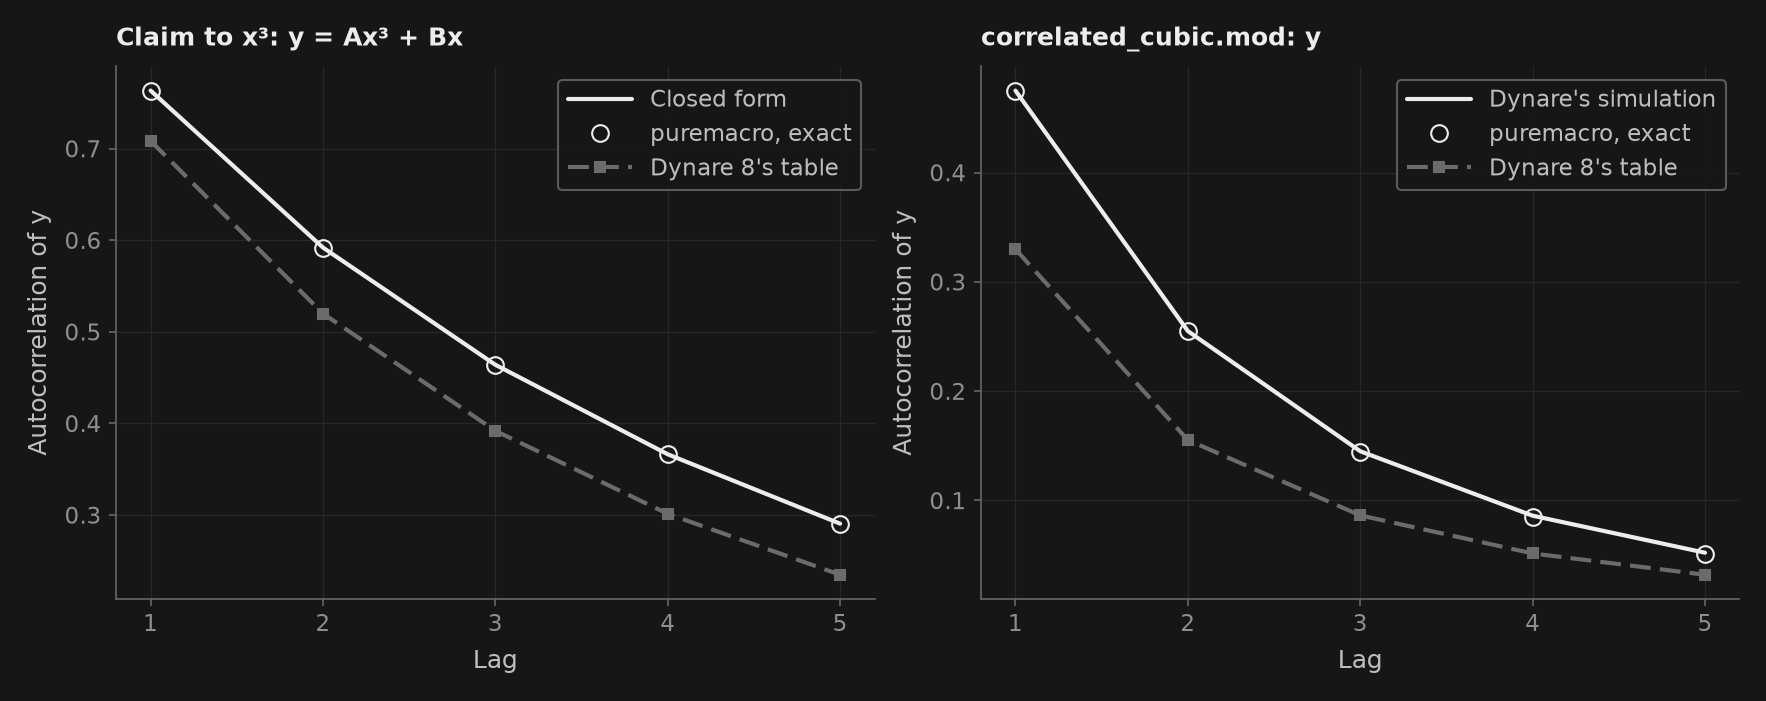

In [9]:
if acf is not None:
    fig, (ax1, ax2) = _nbstyle.figura(1, 2, figsize=(11.5, 4.4))
    dash = _nbstyle.styles(3)
    for ax, key, reference, title in ((ax1, "claim", "closed form", "Claim to x³: y = Ax³ + Bx"),
                                      (ax2, "cubic", "Dynare's simulation", "correlated_cubic.mod: y")):
        frame = acf[key]
        ax.plot(frame.index, frame[reference], color=col[0], lw=2.0, label=reference.capitalize())
        ax.plot(frame.index, frame["puremacro"], "o", color=col[0], mfc="none", ms=8, label="puremacro, exact")
        ax.plot(frame.index, frame["Dynare's table"], color=col[1], lw=2.0, linestyle=dash[1], marker="s", ms=5,
                label="Dynare 8's table")
        ax.set(xlabel="Lag", ylabel="Autocorrelation of y", title=title, xticks=list(frame.index))
        ax.legend(loc="upper right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

### Cuadro de verificación de la replicación

Cada fila da el valor medido y la cota que debía cumplir. Las filas "statistical" se comparan con una simulación y usan una cota sobre el estadístico z; "not run" solo aparece cuando los archivos de Dynare no están disponibles. La línea del veredicto se calcula a partir de las filas.

In [10]:
scorecard = pd.DataFrame(checks)
print(scorecard.to_string(index=False, formatters={"measured": "{:.1e}".format}))
ran = scorecard[scorecard["verdict"] != "not run"]
assert (ran["measured"] <= ran["bound"].astype(float)).all()
missing = len(scorecard) - len(ran)
print(f"\n{len(ran)} of {len(scorecard)} checks ran and pass" + (f"; {missing} need the repository's Dynare fixtures." if missing
      else ". The third-order solver reproduces both closed forms, Dynare's tensors and paths, and Dynare's pruned means"
              " and variances; its exact autocorrelations match Dynare's own simulations rather than Dynare's table."))

                                                                            result measured        bound     verdict
              Exact oracle: claim to x^3, every tensor, 12 calibrations (relative)  3.3e-16 1.000000e-12       exact
                        Exact oracle: Brock-Mirman policy, every tensor (relative)  1.7e-15 1.000000e-12       exact
                     Exact oracle: Brock-Mirman risk terms (certainty equivalence)  2.0e-18 1.000000e-14       exact
                    Dynare 7.0: fixture files whose hash differs from the manifest  0.0e+00 0.000000e+00  provenance
                                        Dynare 7.0: largest tensor error, 10 cases  1.2e-13 1.000000e-10 independent
                                          Dynare 7.0: largest simulated-path error  2.7e-13 1.000000e-10 independent
                                           Dynare 7.0: largest sample-moment error  1.1e-13 1.000000e-10 independent
                  Internal symmetry: RBC g_xxu Schwarz check |g(

## Lectura de los resultados

Ambas formas cerradas se reproducen al nivel del error de redondeo, incluidos los términos de riesgo del derecho cúbico, que la tabla pone junto a los valores que devolvía el solucionador antes de la versión 4.3.0. El modelo de Brock y Mirman devuelve términos de riesgo nulos al nivel del redondeo, como exige la equivalencia cierta de su política exacta. Frente a Dynare, cada tensor de cada modelo coincide dentro de la tolerancia de los archivos de referencia con amplio margen, y lo mismo ocurre con las trayectorias con poda generadas con las propias innovaciones de Dynare y con sus momentos muestrales. Las referencias son números de Dynare, sus hashes coinciden con el manifiesto, y el modelo RBC que se usa después es el mismo archivo que ejecutó Dynare.

La sección 3 muestra por qué las trayectorias simuladas por sí solas no bastan. El error antisimétrico es tan grande en el tensor como el simétrico, pero su efecto sobre la trayectoria simulada es cero al nivel del redondeo porque $\hat x\otimes\hat x\otimes u$ es simétrico en los dos índices de estado. Una comprobación interna de la simetría de Schwarz detecta el error antisimétrico sin referencia externa, mientras que un error simétrico en la derivada cruzada cumple la simetría de Schwarz y exige una comparación entrada por entrada con un oráculo externo.

La sección 4 recuerda que un solucionador confiable puede reportar efectos pequeños y separar sus fuentes. En este modelo RBC la media ergódica del capital está $+0.0785\%$ por encima del estado estacionario determinista con la volatilidad calibrada —impulsada por los términos positivos de curvatura de Jensen en estados y choques, que superan al término de riesgo puro $g_{\sigma\sigma}$, ligeramente negativo— y crece en proporción a la varianza, dentro del error muestral de la simulación. La producción responde de manera asimétrica a choques grandes, un efecto de segundo orden; el tercer orden cambia las respuestas solo un poco, y el nivel de volatilidad apenas mueve la respuesta de impacto del consumo. El derecho sobre $x^3$ es el caso opuesto: en primer y segundo orden su precio ignora las noticias pequeñas, y en tercer orden responde en proporción a la varianza, exactamente como predice la forma cerrada.

La sección 5 aplica las comprobaciones a los momentos. Frente a la forma cerrada del derecho sobre $x^3$, la varianza y las autocorrelaciones de puremacro son exactas al nivel del redondeo, y sus medias y varianzas coinciden con la tabla de Dynare 8 en los seis modelos. Las autocorrelaciones de Dynare son la excepción. Para el precio del derecho, su autocorrelación de orden 1 es 0.7085, mientras que la forma cerrada da 0.7634. En `correlated_cubic.mod` la tabla de Dynare da 0.330, y la simulación del propio Dynare de cuatro millones de períodos da 0.475, como puremacro. Una implementación de referencia puede fallar en un resultado y acertar en el resto. Aquí la tabla de Dynare no pasa la forma cerrada, y sus propias simulaciones también la rechazan.

## Tu turno

Cambia el factor de descuento, la persistencia o la volatilidad del derecho; la aserción compara los términos de riesgo del solucionador con la forma cerrada.

1. **Básico.** Haz negativo `rho_claim` (o fija `rho_claim = 0.0`). ¿Por qué $g_{u\sigma\sigma}=2B$ cambia de signo cuando $\rho<0$ mientras que $g_{x\sigma\sigma}=2B\rho\propto\rho^2$ sigue siendo positivo para todo $\rho\ne 0$ (y ambos se anulan en $\rho=0$)?
2. **Intermedio.** Acerca `beta_claim` a 0.99 con `rho_claim = 0.95`. ¿Qué factor de $B$ explica lo rápido que crecen los términos de riesgo?
3. **Avanzado.** Añade un pago cuadrático, `y = beta*y(+1) + x^3 + c2*x^2`. Deriva la nueva forma cerrada (aparece una constante) y comprueba qué término de riesgo se vuelve distinto de cero en segundo orden.

In [11]:
beta_claim = 0.95   # ← change this: discount factor, 0.5 to 0.99
rho_claim = 0.8     # ← change this: persistence of x, -0.95 to 0.95 (including 0.0)
vol_claim = 0.1     # ← change this: shock standard deviation, 0.01 to 0.5
assert 0.5 <= beta_claim <= 0.99 and -0.95 <= rho_claim <= 0.95 and 0.01 <= vol_claim <= 0.5
_, T = labelled_tensors(claim_to_cube(beta_claim, rho_claim, vol_claim), states=["x"])
A, B, exact = cube_closed_form(beta_claim, rho_claim, vol_claim)
solver = {f: T[f].loc["y"].iloc[0] for f in ("ghxss", "ghuss")}
print(f"B = {B:.6f}; ghxss: solver {solver['ghxss']:.8f}, closed form {exact['ghxss']:.8f}; "
      f"ghuss: solver {solver['ghuss']:.8f}, closed form {exact['ghuss']:.8f}")
assert all(abs(solver[f] - exact[f]) <= 1e-10 * max(1.0, abs(exact[f])) for f in solver)

B = 0.184969; ghxss: solver 0.29595016, closed form 0.29595016; ghuss: solver 0.36993769, closed form 0.36993769


## ¿Qué tan exhaustivo es esto?

Los cuadernos 00 (versión 2.0) y 46 usan poda de segundo orden, y la lección 22 del curso en español grafica respuestas de tercer orden. `docs/es/dsge_higher_order.md` documenta la poda y las respuestas; la comparación en vivo es `tools/reference_validation/validate_dynare.py`, y regenerar los archivos de referencia requiere MATLAB y Dynare. Las comprobaciones de aquí cubren las reglas de decisión, la simulación con poda y la media, la covarianza y las autocorrelaciones exactas. La asimetría y la curtosis no tienen forma cerrada en puremacro: `theoretical_moments()` las reporta como NaN y `ergodic_moments()` las estima con una simulación. Los momentos exactos necesitan un estado aumentado de $3n+2n^2+n^3$ entradas para $n$ estados, así que por defecto se limitan a unos 13 estados. Las preferencias de Epstein-Zin, donde los términos de tercer orden valoran el riesgo, son la siguiente aplicación natural.